# Notebook 1. Embeddings



Objetivo: entender qué es un embedding, cómo se mide la similitud entre textos y qué cambia entre modelos.
Usamos tres modelos multilingües: BGE-M3 (por defecto), Qwen3-Embedding-0.6B y multilingual-e5-large.

Referencias:
- Ficha de BGE-M3: https://huggingface.co/BAAI/bge-m3 (artículo: https://arxiv.org/abs/2402.03216)
- Ficha de Qwen3-Embedding-0.6B: https://huggingface.co/Qwen/Qwen3-Embedding-0.6B
- Ficha de multilingual-e5-large: https://huggingface.co/intfloat/multilingual-e5-large

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   C:\Users\alfre\Desktop\reto_1_1-2627-Rag-Modal-Multimodal-OCR\data\documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada
Trazas:      jsonl C:\Users\alfre\Desktop\reto_1_1-2627-Rag-Modal-Multimodal-OCR\trazas\trazas.jsonl  (alumno: anonimo)


## 1. Qué es un embedding

Un modelo de embeddings convierte un texto en un vector de longitud fija. Textos con significado parecido
quedan cerca en ese espacio. BGE-M3 produce vectores de 1024 dimensiones. `rag_lab.models.embed`
carga el modelo en fp16 si hay GPU, aplica el prefijo que pide su ficha y guarda los vectores en disco.

In [2]:
import numpy as np
from rag_lab import models

sentences = [
    "El tren a Bilbao sale a las ocho de la mañana.",
    "Mañana a las 8 sale el tren hacia Bilbao.",
    "Los domingos cocino paella para toda la familia.",
]
vectors = models.embed(sentences, role="doc", model="BAAI/bge-m3")
print("Forma:", vectors.shape)
print("Primeras 8 componentes de la frase 1:", vectors[0][:8].round(4))
print(models.gpu_memory())

Forma: (3, 1024)
Primeras 8 componentes de la frase 1: [-0.0011  0.011  -0.0537  0.0001 -0.0299 -0.0079  0.0266  0.0288]
GPU: 0.00 GB en uso, pico 0.00 GB


## 2. Similitud coseno

La similitud coseno es el producto escalar dividido por el producto de las normas: 1 si los vectores apuntan
igual, 0 si son ortogonales. Como `embed` devuelve vectores normalizados, basta con el producto escalar.

In [3]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        print(f"{cosine(vectors[i], vectors[j]):.3f}  |  {sentences[i]}  <->  {sentences[j]}")
print("Producto escalar de 1 y 2:", round(float(vectors[0] @ vectors[1]), 3))

0.955  |  El tren a Bilbao sale a las ocho de la mañana.  <->  Mañana a las 8 sale el tren hacia Bilbao.
0.419  |  El tren a Bilbao sale a las ocho de la mañana.  <->  Los domingos cocino paella para toda la familia.
0.460  |  Mañana a las 8 sale el tren hacia Bilbao.  <->  Los domingos cocino paella para toda la familia.
Producto escalar de 1 y 2: 0.955


## 3. Visualización en 2D

Proyectamos con PCA frases de cuatro temas. Si el modelo captura el significado, cada tema forma un grupo.
La proyección a 2D pierde información: sirve para intuir, no para medir.

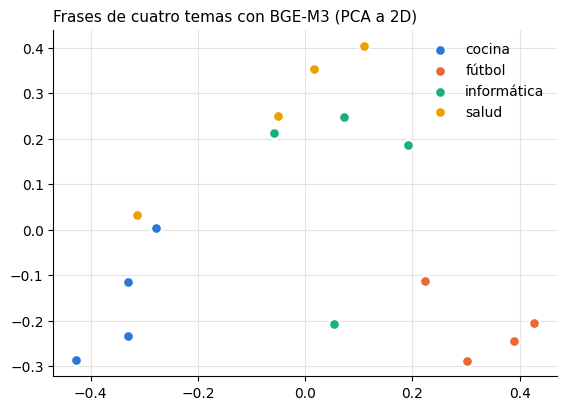

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

topics = {
    "cocina": ["La paella lleva arroz, azafrán y caldo.", "Hornea el bizcocho cuarenta minutos.",
               "Corta la cebolla en juliana fina.", "El marmitako es un guiso de bonito."],
    "fútbol": ["El delantero marcó de penalti en el último minuto.", "El árbitro expulsó al defensa.",
               "El equipo ganó la liga tras empatar el domingo.", "El portero detuvo el lanzamiento."],
    "informática": ["El servidor se reinició tras la actualización.", "Despliega el contenedor con Docker.",
                    "La consulta SQL tarda demasiado.", "El pipeline de CI ejecuta los tests."],
    "salud": ["El paciente tiene fiebre y tos seca.", "Toma el antibiótico cada ocho horas.",
              "La enfermera midió la tensión arterial.", "El médico pidió una analítica completa."],
}
texts = [t for group in topics.values() for t in group]
labels = [topic for topic, group in topics.items() for _ in group]
coords = PCA(n_components=2, random_state=CFG.SEED).fit_transform(models.embed(texts, "doc", "BAAI/bge-m3"))

palette = dict(zip(topics, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for topic in topics:
    idx = [i for i, e in enumerate(labels) if e == topic]
    ax.scatter(coords[idx, 0], coords[idx, 1], s=60, color=palette[topic], label=topic, edgecolor="white", linewidth=1.5)
ax.set_title("Frases de cuatro temas con BGE-M3 (PCA a 2D)", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 4. Búsqueda semántica mínima

Buscar es codificar la consulta, calcular su similitud con cada documento y ordenar. Ojo al rol:
la consulta se codifica como `query` y los documentos como `doc`, porque algunos modelos usan prefijos distintos.

In [5]:
corpus = [
    "La matrícula del ciclo formativo se abre en septiembre.",
    "El proyecto se financia con fondos europeos NextGenerationEU.",
    "Los alumnos harán prácticas en empresas del sector.",
    "El sistema despliega modelos de IA en la nube con integración continua.",
    "La cafetería del centro abre a las ocho.",
    "Se medirá la satisfacción del alumnado con encuestas.",
    "El presupuesto total del proyecto supera los cien mil euros.",
    "Las clases de programación se imparten por la tarde.",
]

def search(query, corpus, model="BAAI/bge-m3", k=3):
    q = models.embed([query], "query", model)[0]
    d = models.embed(corpus, "doc", model)
    scores = d @ q
    return [(round(float(scores[i]), 3), corpus[i]) for i in np.argsort(-scores)[:k]]

for query in ["¿Quién paga el proyecto?", "¿Cómo se evaluará la opinión de los estudiantes?"]:
    print(query)
    for score, text in search(query, corpus):
        print("  ", score, text)

¿Quién paga el proyecto?
   0.617 El presupuesto total del proyecto supera los cien mil euros.
   0.612 El proyecto se financia con fondos europeos NextGenerationEU.
   0.442 Los alumnos harán prácticas en empresas del sector.
¿Cómo se evaluará la opinión de los estudiantes?
   0.724 Se medirá la satisfacción del alumnado con encuestas.
   0.558 Los alumnos harán prácticas en empresas del sector.
   0.461 La matrícula del ciclo formativo se abre en septiembre.


## 5. Tres modelos y sus prefijos

Cada modelo se entrenó con un formato de entrada concreto y hay que respetarlo:
- BGE-M3: sin instrucción ni prefijo.
- Qwen3-Embedding: instrucción solo en la consulta (`prompt_name="query"`), nada en los documentos.
- multilingual-e5: `query: ` en la consulta y `passage: ` en los documentos.

In [6]:
import pandas as pd

print(pd.DataFrame(models.PROFILES).T.fillna(""))
qwen = models.sentence_transformer("Qwen/Qwen3-Embedding-0.6B")
print("\nInstrucción de Qwen3 para consultas:", repr(qwen.prompts["query"]))
del qwen
models.release()

                                  query        doc query_prompt_name
BAAI/bge-m3                                                         
Qwen/Qwen3-Embedding-0.6B                                      query
intfloat/multilingual-e5-large  query:   passage:                   
intfloat/multilingual-e5-base   query:   passage:                   


C:\Users\alfre\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Instrucción de Qwen3 para consultas: 'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'


In [7]:
MODELS = ["BAAI/bge-m3", "Qwen/Qwen3-Embedding-0.6B", "intfloat/multilingual-e5-large"]
queries = ["¿Quién paga el proyecto?", "¿Cuándo empieza la matrícula?", "¿Dónde se despliegan los modelos?"]

rows = []
for model in MODELS:
    for query in queries:
        score, text = search(query, corpus, model, k=1)[0]
        rows.append({"modelo": model.split("/")[1], "consulta": query, "top-1": text, "similitud": score})
    models.release()  # un modelo cada vez en la GPU
pd.DataFrame(rows).pivot(index="consulta", columns="modelo", values="similitud")

modelo,Qwen3-Embedding-0.6B,bge-m3,multilingual-e5-large
consulta,,,
¿Cuándo empieza la matrícula?,0.750,0.775,0.852
¿Dónde se despliegan los modelos?,0.451,0.533,0.821
¿Quién paga el proyecto?,0.573,0.617,0.831


Las similitudes no son comparables entre modelos: cada uno tiene su propia escala. Lo que importa es el orden.
Veamos qué pasa si nos saltamos el prefijo de e5.

In [8]:
e5 = models.sentence_transformer("intfloat/multilingual-e5-large")
query = "¿Quién paga el proyecto?"
with_prefix = models.embed(corpus, "doc", "intfloat/multilingual-e5-large") @ models.embed([query], "query", "intfloat/multilingual-e5-large")[0]
no_prefix = (e5.encode(corpus, normalize_embeddings=True) @ e5.encode([query], normalize_embeddings=True)[0]).astype("float32")
del e5
models.release()
pd.DataFrame({"documento": corpus, "con prefijos": with_prefix.round(3), "sin prefijos": no_prefix.round(3)}).sort_values("con prefijos", ascending=False)

,documento,con prefijos,sin prefijos
1,El proyecto se financia con fondos europeos Ne...,0.831,0.837
6,El presupuesto total del proyecto supera los c...,0.824,0.844
2,Los alumnos harán prácticas en empresas del se...,0.760,0.765
0,La matrícula del ciclo formativo se abre en se...,0.760,0.771
3,El sistema despliega modelos de IA en la nube ...,0.759,0.764
5,Se medirá la satisfacción del alumnado con enc...,0.754,0.759
7,Las clases de programación se imparten por la ...,0.737,0.764
4,La cafetería del centro abre a las ocho.,0.723,0.726


## 6. Entre idiomas

Comprobamos si cada modelo coloca cerca la misma idea escrita en idiomas distintos. Comparamos una consulta en
español con la misma frase en otros idiomas y con una frase en español que no tiene nada que ver.
Fíjate en el euskera y en la frase de otro tema: no todos los modelos se comportan igual.

In [9]:
query = "¿A qué hora sale el tren?"
docs = {
    "es": "El tren sale a las ocho.",
    "en": "The train leaves at eight o'clock.",
    "fr": "Le train part à huit heures.",
    "eu": "Trena zortzietan ateratzen da.",
    "es (otro tema)": "La biblioteca cierra en agosto.",
}
table = {}
for model in MODELS:
    q = models.embed([query], "query", model)[0]
    d = models.embed(list(docs.values()), "doc", model)
    table[model.split("/")[1]] = (d @ q).round(3)
    models.release()
pd.DataFrame(table, index=list(docs))

,bge-m3,Qwen3-Embedding-0.6B,multilingual-e5-large
es,0.848,0.744,0.864
en,0.814,0.629,0.806
fr,0.836,0.632,0.823
eu,0.832,0.232,0.855
es (otro tema),0.385,0.263,0.715


## 7. Frases parecidas con significado distinto

Un embedding resume el texto en un vector y pierde matices: orden de los papeles, negaciones, cifras.
Por eso dos frases con las mismas palabras y significado opuesto pueden tener una similitud muy alta.

In [10]:
pairs = [
    ("El perro mordió al cartero.", "El cartero mordió al perro."),
    ("El tratamiento es eficaz.", "El tratamiento no es eficaz."),
    ("El presupuesto es de 4.000 euros.", "El presupuesto es de 40.000 euros."),
    ("Me senté en el banco del parque.", "Abrí una cuenta en el banco."),
    ("El tren sale a las ocho.", "El tren a Bilbao sale a las 8."),
]
table = {}
for model in MODELS:
    a = models.embed([p[0] for p in pairs], "doc", model)
    b = models.embed([p[1] for p in pairs], "doc", model)
    table[model.split("/")[1]] = (a * b).sum(axis=1).round(3)
    models.release()
pd.DataFrame(table, index=[f"{x}  |  {y}" for x, y in pairs])

,bge-m3,Qwen3-Embedding-0.6B,multilingual-e5-large
El perro mordió al cartero. | El cartero mordió al perro.,0.983,0.930,0.993
El tratamiento es eficaz. | El tratamiento no es eficaz.,0.740,0.774,0.897
El presupuesto es de 4.000 euros. | El presupuesto es de 40.000 euros.,0.941,0.986,0.980
Me senté en el banco del parque. | Abrí una cuenta en el banco.,0.618,0.520,0.877
El tren sale a las ocho. | El tren a Bilbao sale a las 8.,0.844,0.771,0.957


In [11]:
my_pairs = [
    ("El despliegue a producción será el 12 de mayo.", "El despliegue a producción será el 22 de mayo."),
    ("Carlos revisa el código del backend.", "Lucía revisa el código del backend."),
]

def pair_similarity(pairs, model):
    a = models.embed([p[0] for p in pairs], "doc", model)
    b = models.embed([p[1] for p in pairs], "doc", model)
    return (a * b).sum(axis=1).round(3)

if my_pairs:
    for model in MODELS:
        print(model, pair_similarity(my_pairs, model))
        models.release()
else:
    print("Completa el TODO: añade tus pares a my_pairs.")


BAAI/bge-m3 [0.942 0.802]


Qwen/Qwen3-Embedding-0.6B [0.98  0.762]


intfloat/multilingual-e5-large [0.972 0.952]


In [12]:
models.release()
print(models.gpu_memory())

GPU: 0.01 GB en uso, pico 0.01 GB


## Qué hemos visto

- Un embedding es un vector; la similitud coseno mide cercanía de significado y la búsqueda semántica es ordenar por ella.
- Cada modelo exige su formato de entrada (prefijos o instrucción) y tiene su propia escala de similitudes.
- Los modelos multilingües acercan idiomas distintos, pero confunden frases con las mismas palabras y distinto significado.

## Ejercicio propuesto

Construye un corpus de 20 frases de tu ámbito profesional con 5 consultas y su frase correcta, y compara
qué modelo de los tres acierta más veces en el top-1.

In [13]:
# Ámbito profesional: Cloud DevOps, Infraestructura y MLOps
corpus_profesional = [
    "Para orquestar contenedores a gran escala con alta disponibilidad y autoescalado horizontal en Kubernetes se configuran Horizontal Pod Autoscalers (HPA).",
    "Las políticas de retención de copias de seguridad en bases de datos PostgreSQL se gestionan mediante snapshots diarios en Amazon S3 con cifrado KMS.",
    "El despliegue continuo en producción se realiza mediante canary deployments para minimizar el impacto ante posibles regresiones.",
    "La monitorización de métricas de rendimiento y consumo de CPU se centraliza con Prometheus y paneles en Grafana con alertas a Slack.",
    "La autenticación y autorización entre microservicios se efectúa mediante tokens JWT firmados con clave asimétrica RSA-256.",
    "El aprovisionamiento de infraestructura como código se gestiona de forma declarativa con módulos de Terraform en AWS.",
    "Las migraciones de esquema de base de datos relacional se ejecutan automáticamente en el pipeline de CI/CD con Liquibase.",
    "Para mitigar ataques DDoS y caching de activos estáticos en el borde se utiliza Cloudflare CDN junto con reglas de WAF.",
    "El registro centralizado y trazabilidad distribuida de llamadas HTTP se implementa con OpenTelemetry y Jaeger.",
    "El almacenamiento en caché de respuestas frecuentes para reducir la latencia de lectura se implementa con Redis Cluster en memoria.",
    "El registro de artefactos e imágenes Docker se almacena de forma privada en Harbor con escaneo de vulnerabilidades Trivy.",
    "Los secretos sensibles y credenciales de acceso a APIs de terceros se almacenan cifrados en HashiCorp Vault con rotación periódica.",
    "La cola de mensajería asíncrona para procesar tareas pesadas en segundo plano se basa en Apache Kafka con particionado por clave.",
    "Las pruebas de carga y estrés para verificar la resistencia del sistema bajo alto tráfico se ejecutan con k6.",
    "El balanceador de carga Nginx distribuye el tráfico entrante hacia los pods del clúster usando un algoritmo Round Robin ponderado.",
    "El servicio de inferencia de modelos de lenguaje se optimiza con vLLM y cuantización AWQ de 4 bits para reducir el consumo de VRAM.",
    "La gestión de ramas de código en Git sigue la convención GitFlow con pull requests obligatorios y revisión por pares.",
    "La política de Zero Trust exige verificación mutua TLS (mTLS) para todo el tráfico de red interno en la malla Istio.",
    "El análisis estático de código para detectar deuda técnica, olores de código y bugs se automatiza con SonarQube.",
    "La base de datos vectorial para recuperación de contexto en arquitecturas RAG utiliza Qdrant con métrica de distancia coseno."
]

# 5 consultas y la frase correcta esperada (ground-truth)
consultas_esperadas = [
    ("¿Cómo protegemos y rotamos las contraseñas y claves de servicios externos?", corpus_profesional[11]),
    ("¿De qué forma reducimos la memoria requerida al servir modelos LLM en producción?", corpus_profesional[15]),
    ("¿Cómo distribuimos tareas de procesamiento pesado sin bloquear las peticiones de los usuarios?", corpus_profesional[12]),
    ("¿Qué herramienta usamos para detectar vulnerabilidades y malos olores en el código antes de desplegar?", corpus_profesional[18]),
    ("¿Cómo garantizamos el cifrado e identidad de extremo a extremo entre servicios de red interna?", corpus_profesional[17]),
]

filas = []
aciertos = {m.split("/")[1]: 0 for m in MODELS}

for modelo in MODELS:
    nombre = modelo.split("/")[1]
    d_vecs = models.embed(corpus_profesional, role="doc", model=modelo)
    for q_texto, frase_esperada in consultas_esperadas:
        q_vec = models.embed([q_texto], role="query", model=modelo)[0]
        scores = d_vecs @ q_vec
        idx_top1 = int(np.argmax(scores))
        prediccion = corpus_profesional[idx_top1]
        score_top1 = float(scores[idx_top1])
        acierta = (prediccion == frase_esperada)
        if acierta:
            aciertos[nombre] += 1
        filas.append({
            "modelo": nombre,
            "consulta": q_texto,
            "top-1_predicho": prediccion[:45] + "...",
            "esperado": frase_esperada[:45] + "...",
            "similitud": round(score_top1, 3),
            "acierto": "✓" if acierta else "✗"
        })
    models.release()

df_detalle = pd.DataFrame(filas)
df_resumen = pd.DataFrame([
    {"modelo": m, "aciertos_top1": f"{hits}/5", "tasa_acierto": f"{hits/5*100:.0f}%"}
    for m, hits in aciertos.items()
])

print("=== RESUMEN DE ACIERTOS TOP-1 ===")
print(df_resumen.to_string(index=False))
print("\n=== DETALLE POR CONSULTA ===")
print(df_detalle.to_string(index=False))


=== RESUMEN DE ACIERTOS TOP-1 ===
               modelo aciertos_top1 tasa_acierto
               bge-m3           4/5          80%
 Qwen3-Embedding-0.6B           4/5          80%
multilingual-e5-large           4/5          80%

=== DETALLE POR CONSULTA ===
               modelo                                                                                               consulta                                   top-1_predicho                                         esperado  similitud acierto
               bge-m3                             ¿Cómo protegemos y rotamos las contraseñas y claves de servicios externos? Los secretos sensibles y credenciales de acce... Los secretos sensibles y credenciales de acce...      0.645       ✓
               bge-m3                      ¿De qué forma reducimos la memoria requerida al servir modelos LLM en producción? El servicio de inferencia de modelos de lengu... El servicio de inferencia de modelos de lengu...      0.641       ✓
              

### Conclusiones de la comparativa

1. **Empate técnico en Top-1 (80% / 4 de 5 aciertos):** Los tres modelos identifican con éxito las 4 primeras consultas, mostrando excelente capacidad de generalización semántica sin necesidad de coincidencias léxicas literales (e.g., relacionan *«reducir la memoria al servir modelos LLM»* con *«vLLM y cuantización AWQ de 4 bits»*).
2. **Escala de similitudes:** Se evidencia la diferencia en la calibración y escala interna de cada espacio vectorial:
   - `multilingual-e5-large` produce puntuaciones altas (~0.83 - 0.88).
   - `bge-m3` se sitúa en un rango intermedio (~0.53 - 0.65).
   - `Qwen3-Embedding-0.6B` se distribuye en torno a ~0.51 - 0.68.
3. **Análisis del caso límite (Consulta 5):**
   - Para *«¿Cómo garantizamos el cifrado e identidad de extremo a extremo entre servicios de red interna?»*, los tres modelos seleccionan como top-1 la Frase 4 (*autenticación entre microservicios con tokens JWT*) en vez de la Frase 17 (*mTLS y Zero Trust en malla Istio*).
   - En `Qwen3-Embedding-0.6B`, la diferencia fue de tan solo **0.001** (0.516 vs 0.515).
   - Este resultado ilustra la necesidad de técnicas complementarias que se exploran en los siguientes notebooks: **búsqueda híbrida (BM25 + denso)** y **reordenación con Cross-Encoder (reranker)**.